# 2. Descriptive statistics

Summarize numeric variables with measures of central tendency and spread, then examine skewness and kurtosis.

In [3]:
from pathlib import Path

import pandas as pd

DATASET_PATH = Path("../data/processed/cardekho_cleaned.csv")
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Place the cleaned CarDekho CSV at {DATASET_PATH.resolve()}")

df = pd.read_csv(DATASET_PATH)
numeric = df.select_dtypes(include="number")
summary = numeric.describe().T
summary["median"] = numeric.median()
summary["skewness"] = numeric.skew()
summary["kurtosis"] = numeric.kurt()
display(summary)

FileNotFoundError: Place the cleaned CarDekho CSV at C:\Users\USER\Documents\YEAR 3 TERM 1\Data Visulaization\Week3\car_price_prediction\Car_Sale_Analysis\data\processed\cardekho_cleaned.csv

In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv(r"C:\Users\USER\Documents\YEAR 3 TERM 1\Data Visulaization\Week3\car_price_prediction\Car_Sale_Analysis\data\cardekho_cleaned.csv")

df.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,...,real_avg_owner_count,real_model_variant_count,real_common_trim,matched_dt,real_new_ex_showroom_price,real_body_type,matched_eng,km_per_year,brand_tier,model_grouped
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,13333.33,Economy,Alto
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,...,1.08,25.0,i10 Sportz,1.0,0.641574,Hatchback,1.0,4000.00,Economy,Grand
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,...,1.18,67.0,1.2 Magna,1.0,0.820343,Hatchback,1.0,5454.55,Economy,i20
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,4111.11,Economy,Alto
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,...,1.08,28.0,1.5 DV5 MT Titanium Optional,1.0,0.856000,SUV,1.0,5000.00,Mid,Ecosport


In [5]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)

(15244, 25)
['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price', 'real_primary_city', 'real_typical_owner_type', 'real_avg_owner_count', 'real_model_variant_count', 'real_common_trim', 'matched_dt', 'real_new_ex_showroom_price', 'real_body_type', 'matched_eng', 'km_per_year', 'brand_tier', 'model_grouped']
car_name                          str
brand                             str
model                             str
vehicle_age                     int64
km_driven                       int64
seller_type                       str
fuel_type                         str
transmission_type                 str
mileage                       float64
engine                          int64
max_power                     float64
seats                           int64
selling_price                   int64
real_primary_city                 str
real_typical_owner_type           str
real_av

In [6]:
df.describe()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price,real_avg_owner_count,real_model_variant_count,matched_dt,real_new_ex_showroom_price,matched_eng,km_per_year
count,15244.000000,1.524400e+04,15244.000000,15244.000000,15244.000000,15244.000000,1.524400e+04,14940.000000,14940.000000,14940.0,9924.000000,9924.0,15244.000000
mean,6.041131,5.563958e+04,19.697333,1486.171543,100.607652,5.326817,7.747014e+05,1.152581,29.254418,1.0,0.479353,1.0,9860.322623
std,3.016228,5.176630e+04,4.169307,520.419390,42.915687,0.806464,8.946761e+05,0.086761,17.738761,0.0,0.294189,0.0,9587.128536
min,0.000000,1.000000e+02,4.000000,793.000000,38.400000,2.000000,4.000000e+04,1.000000,1.000000,1.0,0.125000,1.0,100.000000
25%,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05,1.080000,16.000000,1.0,0.144950,1.0,5833.330000
50%,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.590000e+05,1.150000,25.000000,1.0,0.519500,1.0,8428.570000
75%,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05,1.190000,39.000000,1.0,0.814000,1.0,12166.670000
max,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07,1.750000,67.000000,1.0,0.990000,1.0,760000.000000


In [7]:
df.isnull().sum()

car_name                         0
brand                            0
model                            0
vehicle_age                      0
km_driven                        0
seller_type                      0
fuel_type                        0
transmission_type                0
mileage                          0
engine                           0
max_power                        0
seats                            0
selling_price                    0
real_primary_city                0
real_typical_owner_type          0
real_avg_owner_count           304
real_model_variant_count       304
real_common_trim                 0
matched_dt                     304
real_new_ex_showroom_price    5320
real_body_type                   0
matched_eng                   5320
km_per_year                      0
brand_tier                       0
model_grouped                    0
dtype: int64

In [8]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': missing_percent
})

missing_summary[missing_summary['Missing_Count'] > 0]

,Missing_Count,Missing_Percentage
real_avg_owner_count,304,1.994227
real_model_variant_count,304,1.994227
matched_dt,304,1.994227
real_new_ex_showroom_price,5320,34.898977
matched_eng,5320,34.898977


In [9]:
# Display rows with missing values
df[df.isnull().any(axis=1)].head(10)

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,...,real_avg_owner_count,real_model_variant_count,real_common_trim,matched_dt,real_new_ex_showroom_price,real_body_type,matched_eng,km_per_year,brand_tier,model_grouped
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,13333.33,Economy,Alto
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,4111.11,Economy,Alto
5,Maruti Wagon R,Maruti,Wagon R,8,35000,Individual,Petrol,Manual,18.90,998,...,1.21,34.0,R VXI,1.0,NaN,Unknown,NaN,4375.00,Economy,Wagon R
7,Maruti Wagon R,Maruti,Wagon R,3,17512,Dealer,Petrol,Manual,20.51,998,...,1.21,34.0,R VXI,1.0,NaN,Unknown,NaN,5837.33,Economy,Wagon R
8,Hyundai Venue,Hyundai,Venue,2,20000,Individual,Petrol,Automatic,18.15,998,...,NaN,NaN,Unknown,NaN,0.826,SUV,1.0,10000.00,Economy,Venue
9,Maruti Swift,Maruti,Swift,4,28321,Dealer,Petrol,Manual,16.60,1197,...,1.17,59.0,VDI,1.0,NaN,Unknown,NaN,7080.25,Economy,Swift
13,Maruti Ciaz,Maruti,Ciaz,5,76000,Dealer,Diesel,Manual,28.09,1248,...,1.07,23.0,ZDi Plus SHVS,1.0,NaN,Unknown,NaN,15200.00,Economy,Ciaz
14,Maruti Swift,Maruti,Swift,5,20000,Individual,Diesel,Manual,25.20,1248,...,1.17,59.0,VDI,1.0,NaN,Unknown,NaN,4000.00,Economy,Swift
15,Mercedes-Benz C-Class,Mercedes-Benz,C-Class,7,65000,Dealer,Diesel,Automatic,19.27,2143,...,1.22,30.0,C-Class C 220d Avantgarde Edition C,1.0,NaN,Unknown,NaN,9285.71,Luxury,C-Class
16,Maruti Swift,Maruti,Swift,7,62200,Dealer,Diesel,Manual,28.40,1248,...,1.17,59.0,VDI,1.0,NaN,Unknown,NaN,8885.71,Economy,Swift


In [10]:
# Check whether missing values occur together
df[df["real_new_ex_showroom_price"].isnull()][
    ["car_name", "brand", "model", "matched_eng",
     "real_new_ex_showroom_price"]
].head(10)

,car_name,brand,model,matched_eng,real_new_ex_showroom_price
0,Maruti Alto,Maruti,Alto,NaN,NaN
3,Maruti Alto,Maruti,Alto,NaN,NaN
5,Maruti Wagon R,Maruti,Wagon R,NaN,NaN
7,Maruti Wagon R,Maruti,Wagon R,NaN,NaN
9,Maruti Swift,Maruti,Swift,NaN,NaN
13,Maruti Ciaz,Maruti,Ciaz,NaN,NaN
14,Maruti Swift,Maruti,Swift,NaN,NaN
15,Mercedes-Benz C-Class,Mercedes-Benz,C-Class,NaN,NaN
16,Maruti Swift,Maruti,Swift,NaN,NaN
18,Maruti Baleno,Maruti,Baleno,NaN,NaN


In [12]:
df[[
    "real_avg_owner_count",
    "real_model_variant_count"
]].describe()

,real_avg_owner_count,real_model_variant_count
count,14940.000000,14940.000000
mean,1.152581,29.254418
std,0.086761,17.738761
min,1.000000,1.000000
25%,1.080000,16.000000
50%,1.150000,25.000000
75%,1.190000,39.000000
max,1.750000,67.000000


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
df["real_avg_owner_count"] = df["real_avg_owner_count"].fillna(
    df["real_avg_owner_count"].median()
)

df["real_model_variant_count"] = df["real_model_variant_count"].fillna(
    df["real_model_variant_count"].median()
)

In [15]:

print(df[[
    "real_avg_owner_count",
    "real_model_variant_count"
]].isnull().sum())

real_avg_owner_count        0
real_model_variant_count    0
dtype: int64


In [16]:
# Select numerical columns
numerical_df = df.select_dtypes(include=["number"])

# Display numerical columns
print(numerical_df.columns.tolist())

['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price', 'real_avg_owner_count', 'real_model_variant_count', 'matched_dt', 'real_new_ex_showroom_price', 'matched_eng', 'km_per_year']


In [18]:
numerical_columns = [
    "vehicle_age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats",
    "selling_price",
    "real_avg_owner_count",
    "real_model_variant_count",
    "matched_dt",
    "real_new_ex_showroom_price",
    "matched_eng",
    "km_per_year"
]

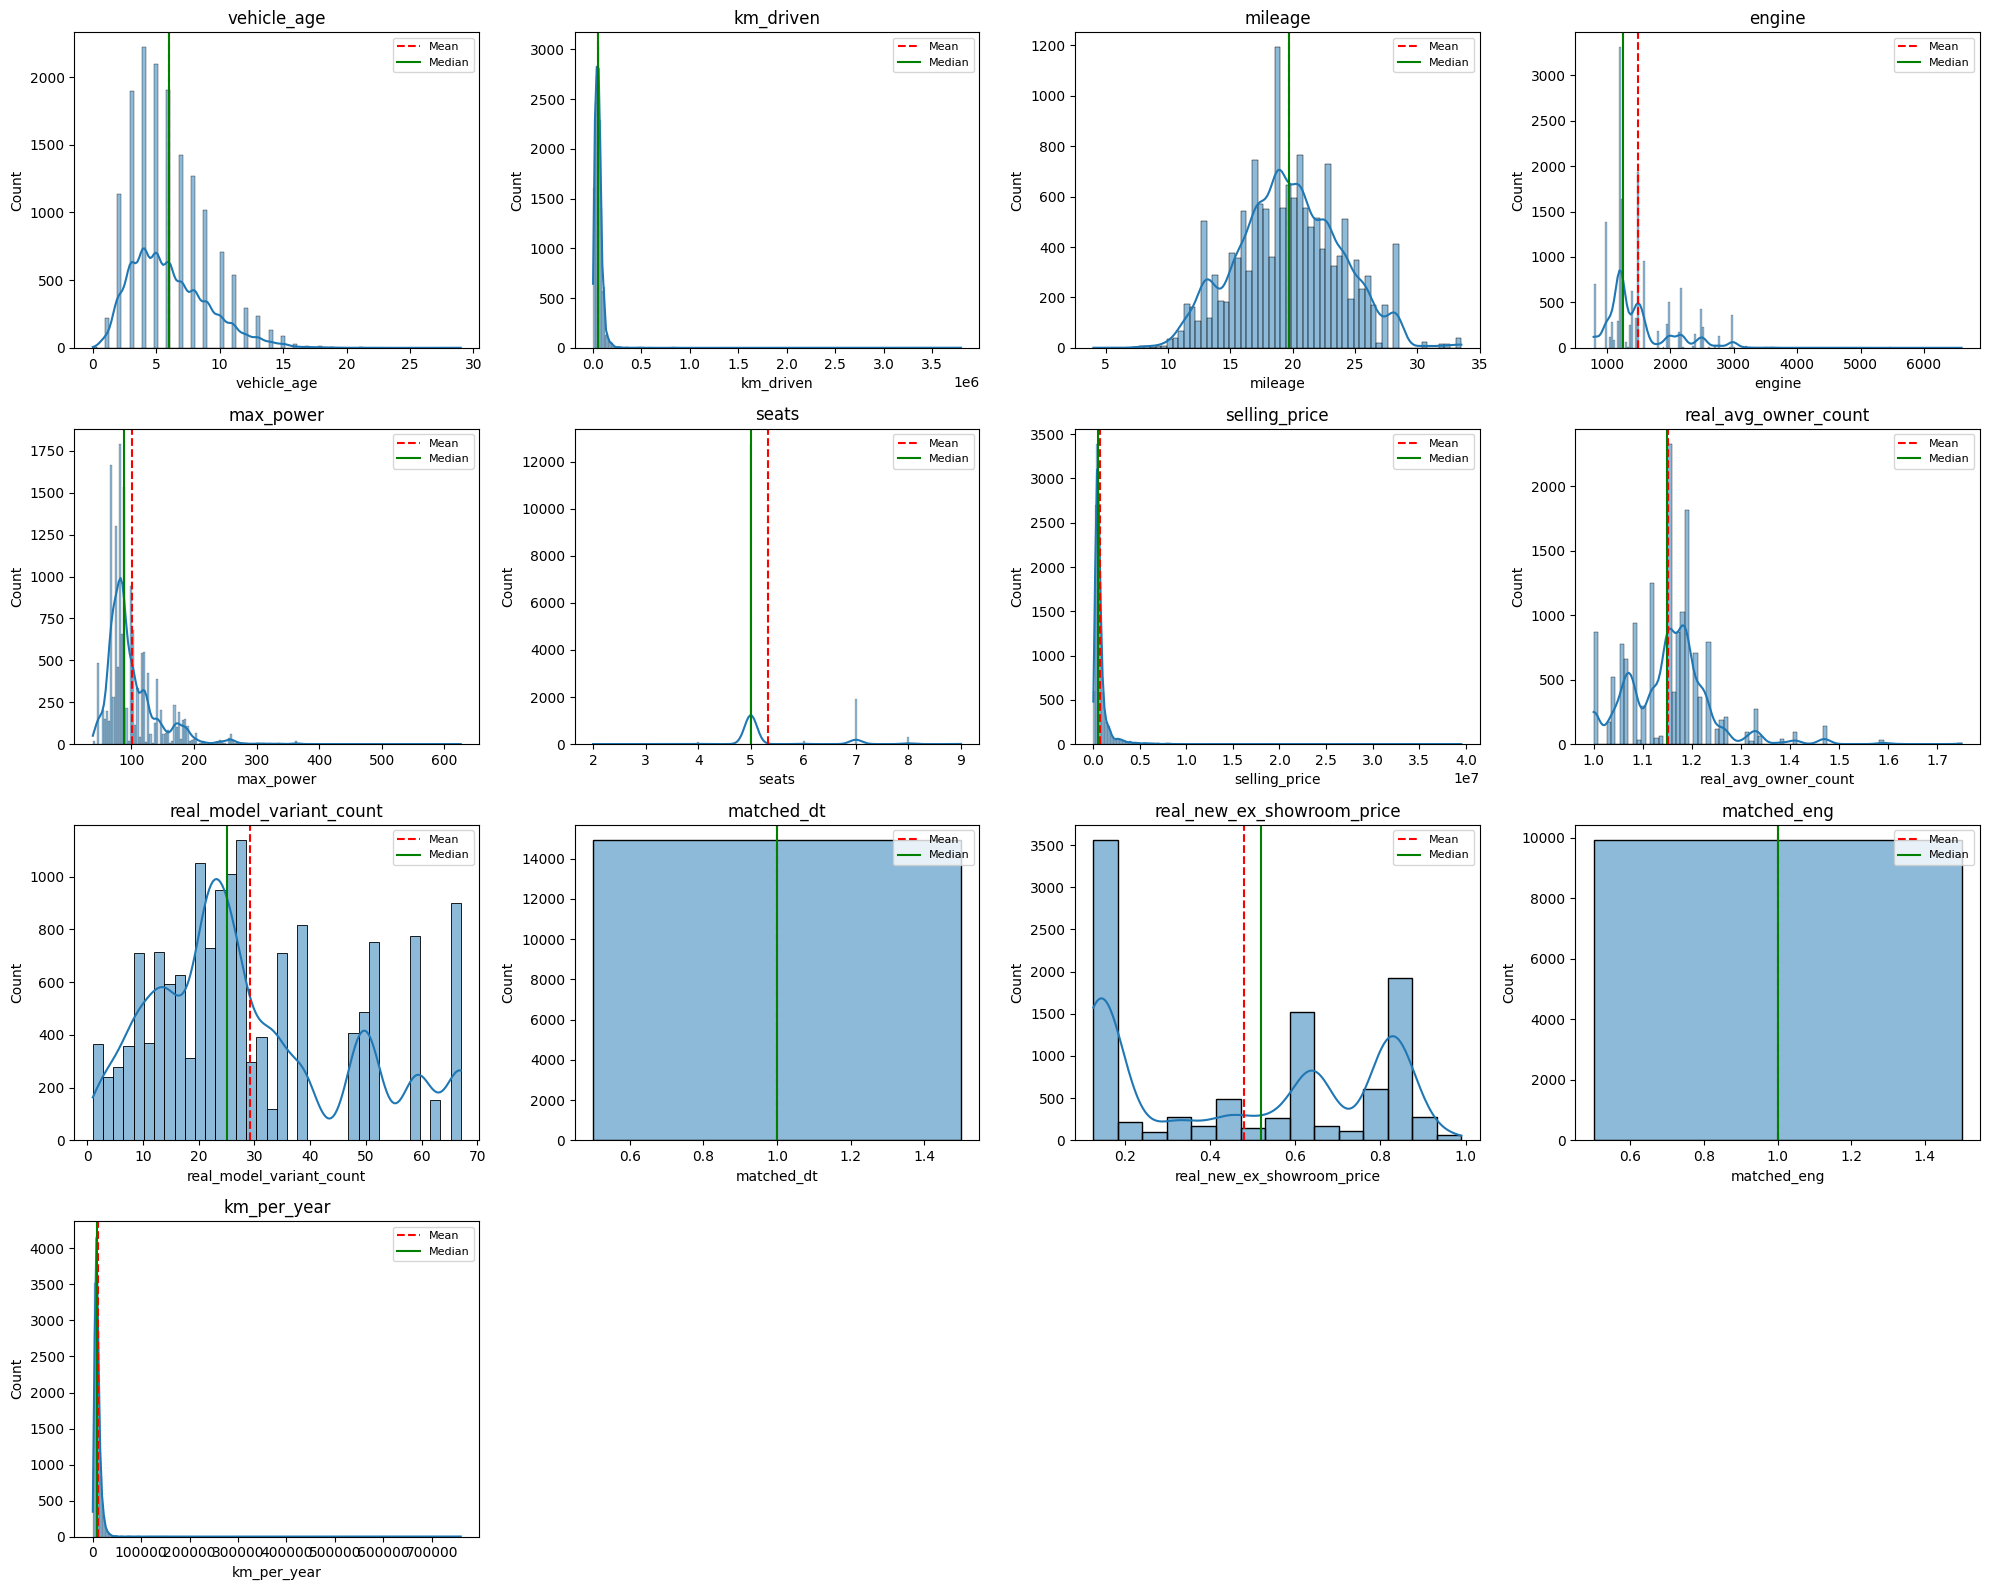

In [19]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for ax, col in zip(axes.flatten(), numerical_columns):

    data = pd.to_numeric(df[col], errors="coerce").dropna()

    mean_value = data.mean()
    median_value = data.median()

    sns.histplot(data, kde=True, ax=ax)

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        label="Mean"
    )

    ax.axvline(
        median_value,
        color="green",
        linestyle="-",
        label="Median"
    )

    ax.set_title(col)
    ax.legend(fontsize=8)

# Hide unused plots
for ax in axes.flatten()[len(numerical_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

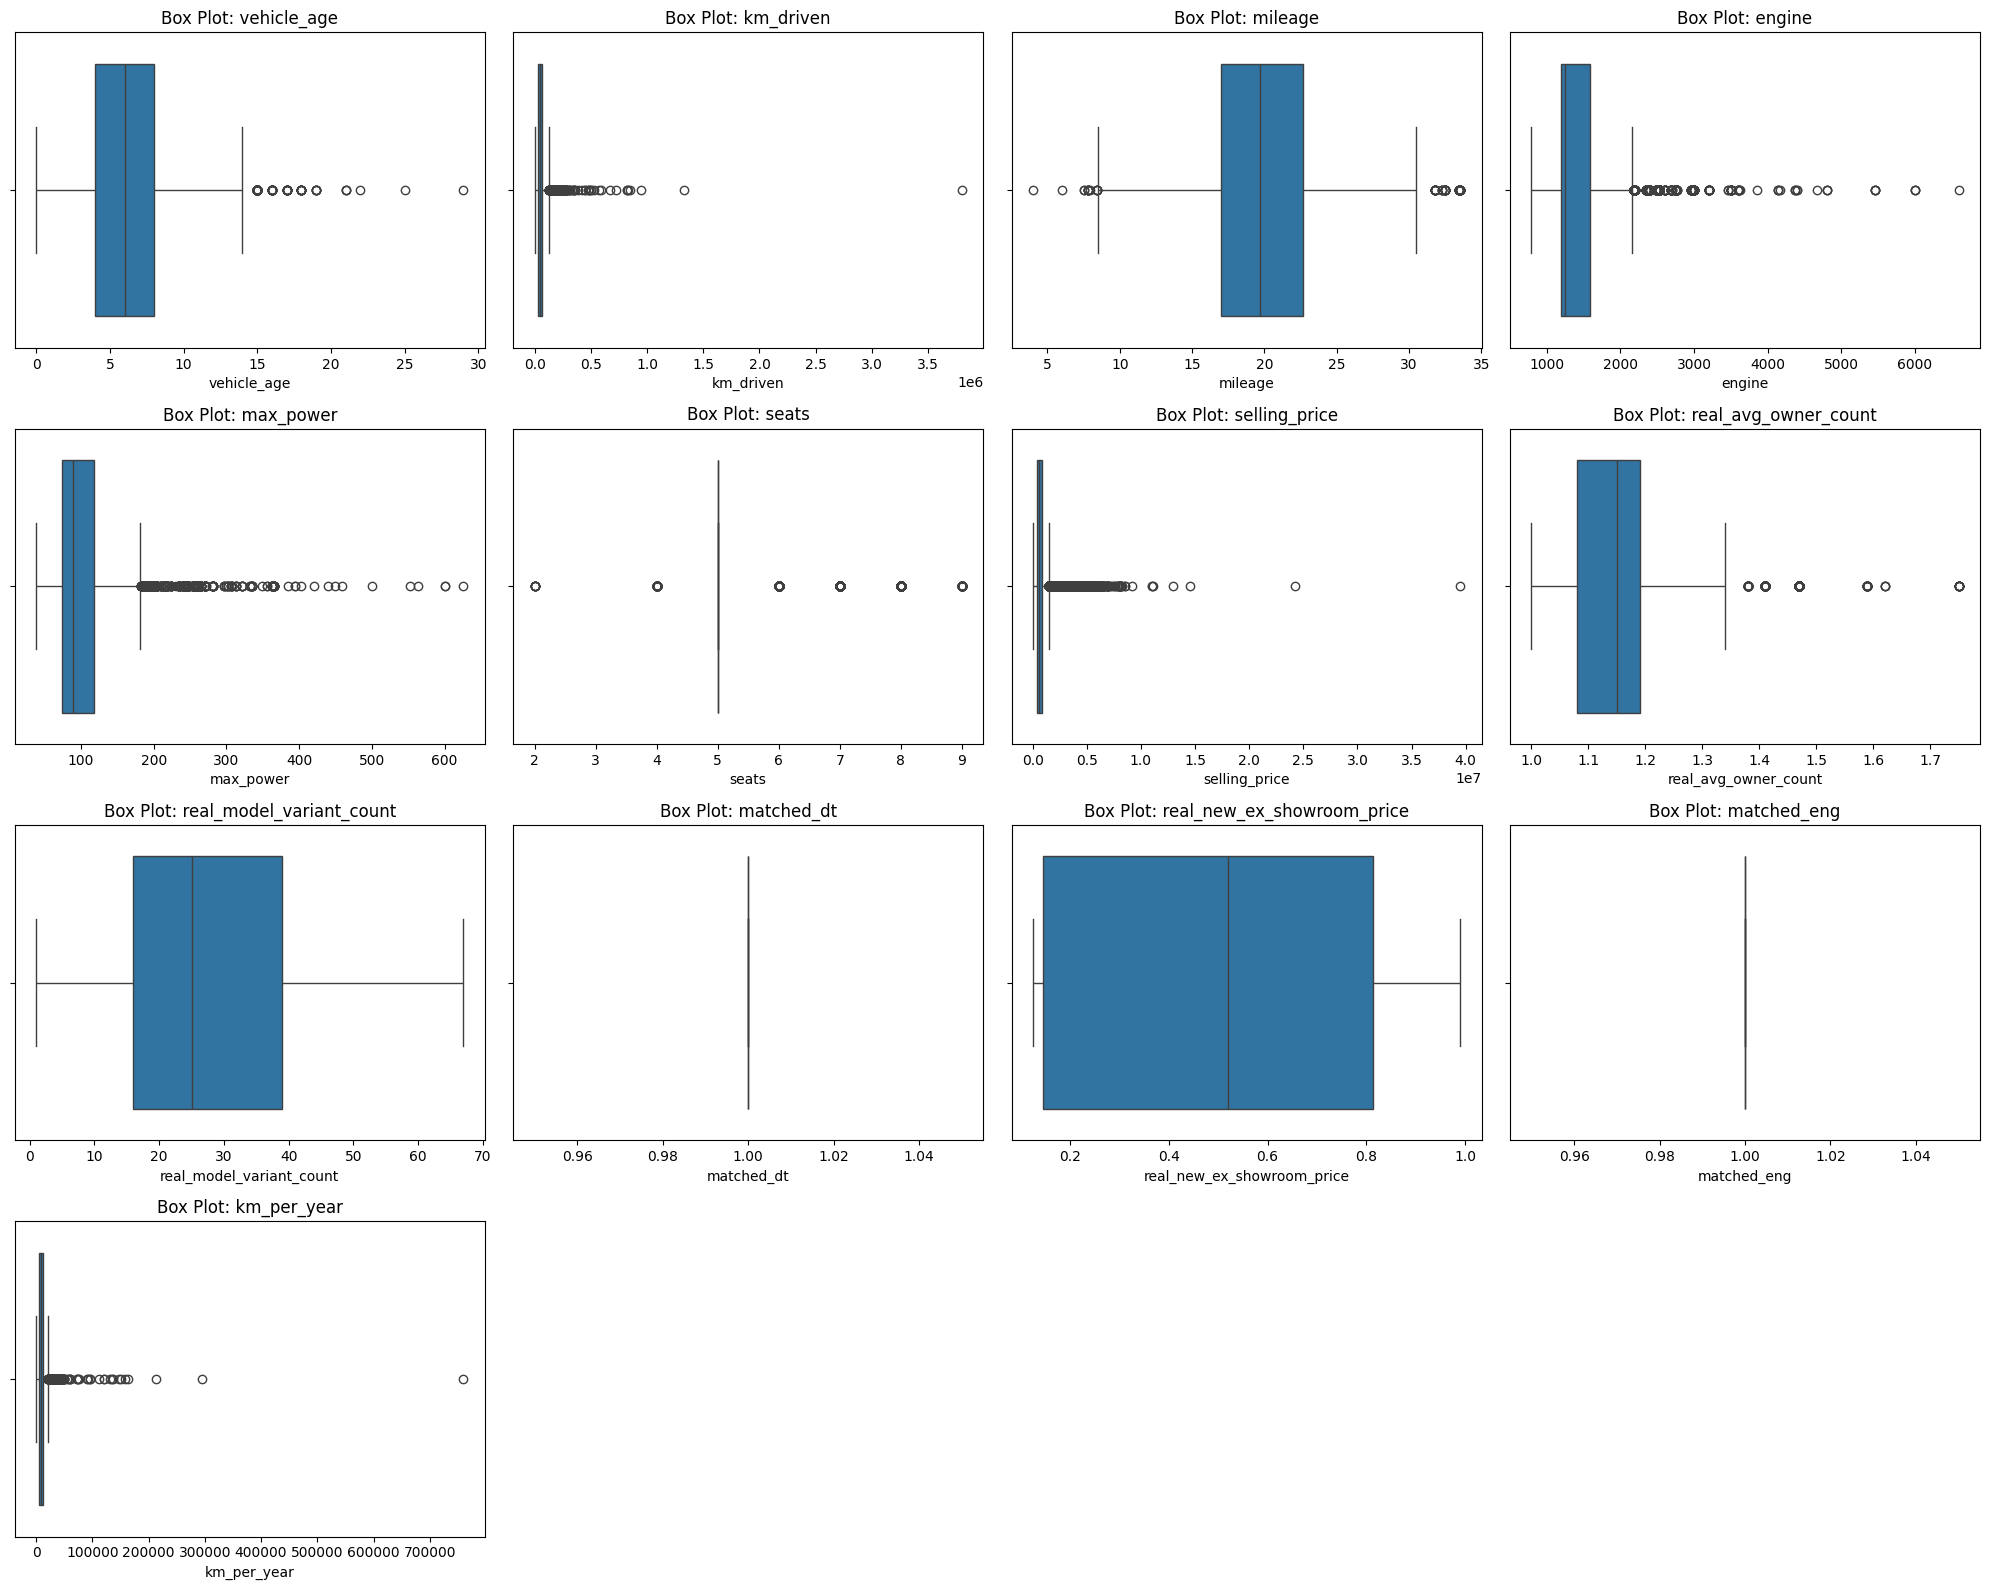

In [20]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for ax, col in zip(axes.flatten(), numerical_columns):

    data = pd.to_numeric(df[col], errors="coerce").dropna()

    sns.boxplot(x=data, ax=ax)

    ax.set_title(f"Box Plot: {col}")
    ax.set_xlabel(col)

for ax in axes.flatten()[len(numerical_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

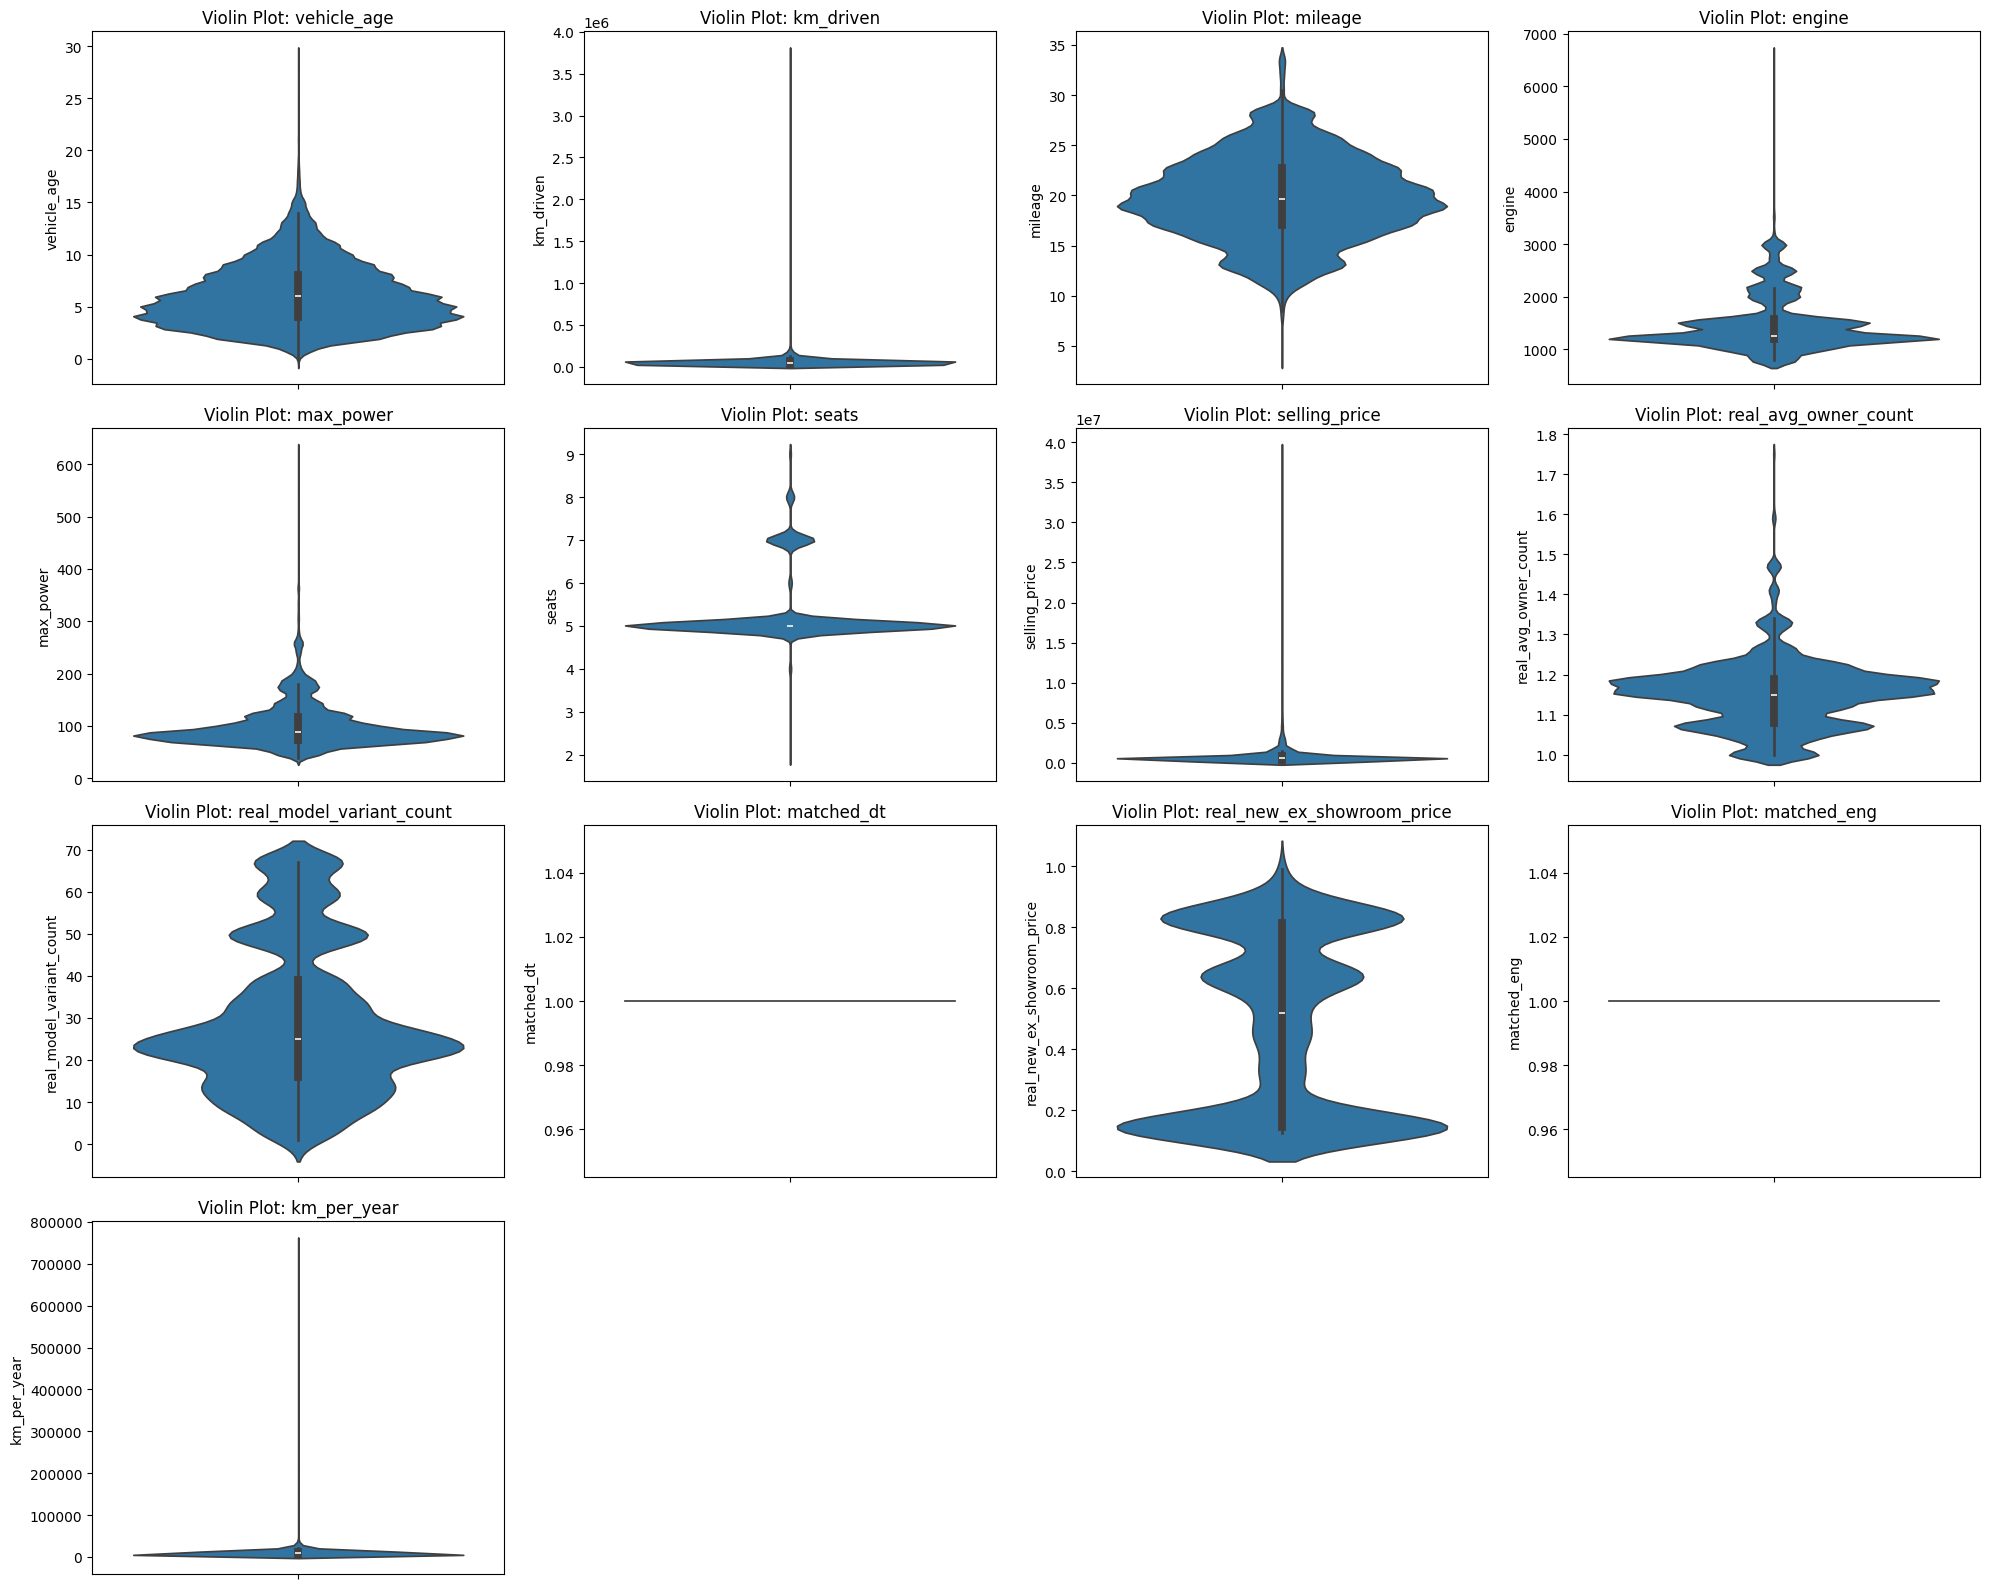

In [21]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for ax, col in zip(axes.flatten(), numerical_columns):

    data = pd.to_numeric(df[col], errors="coerce").dropna()

    sns.violinplot(y=data, ax=ax)

    ax.set_title(f"Violin Plot: {col}")
    ax.set_ylabel(col)

for ax in axes.flatten()[len(numerical_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [22]:
skewness = df[numerical_columns].skew()

print("Skewness of numerical variables:")
print(skewness.sort_values(ascending=False).round(3))

Skewness of numerical variables:
km_per_year                   36.022
km_driven                     28.229
selling_price                 10.109
max_power                      2.487
seats                          2.091
engine                         1.669
real_avg_owner_count           1.008
vehicle_age                    0.834
real_model_variant_count       0.666
mileage                        0.110
real_new_ex_showroom_price     0.004
matched_dt                     0.000
matched_eng                    0.000
dtype: float64


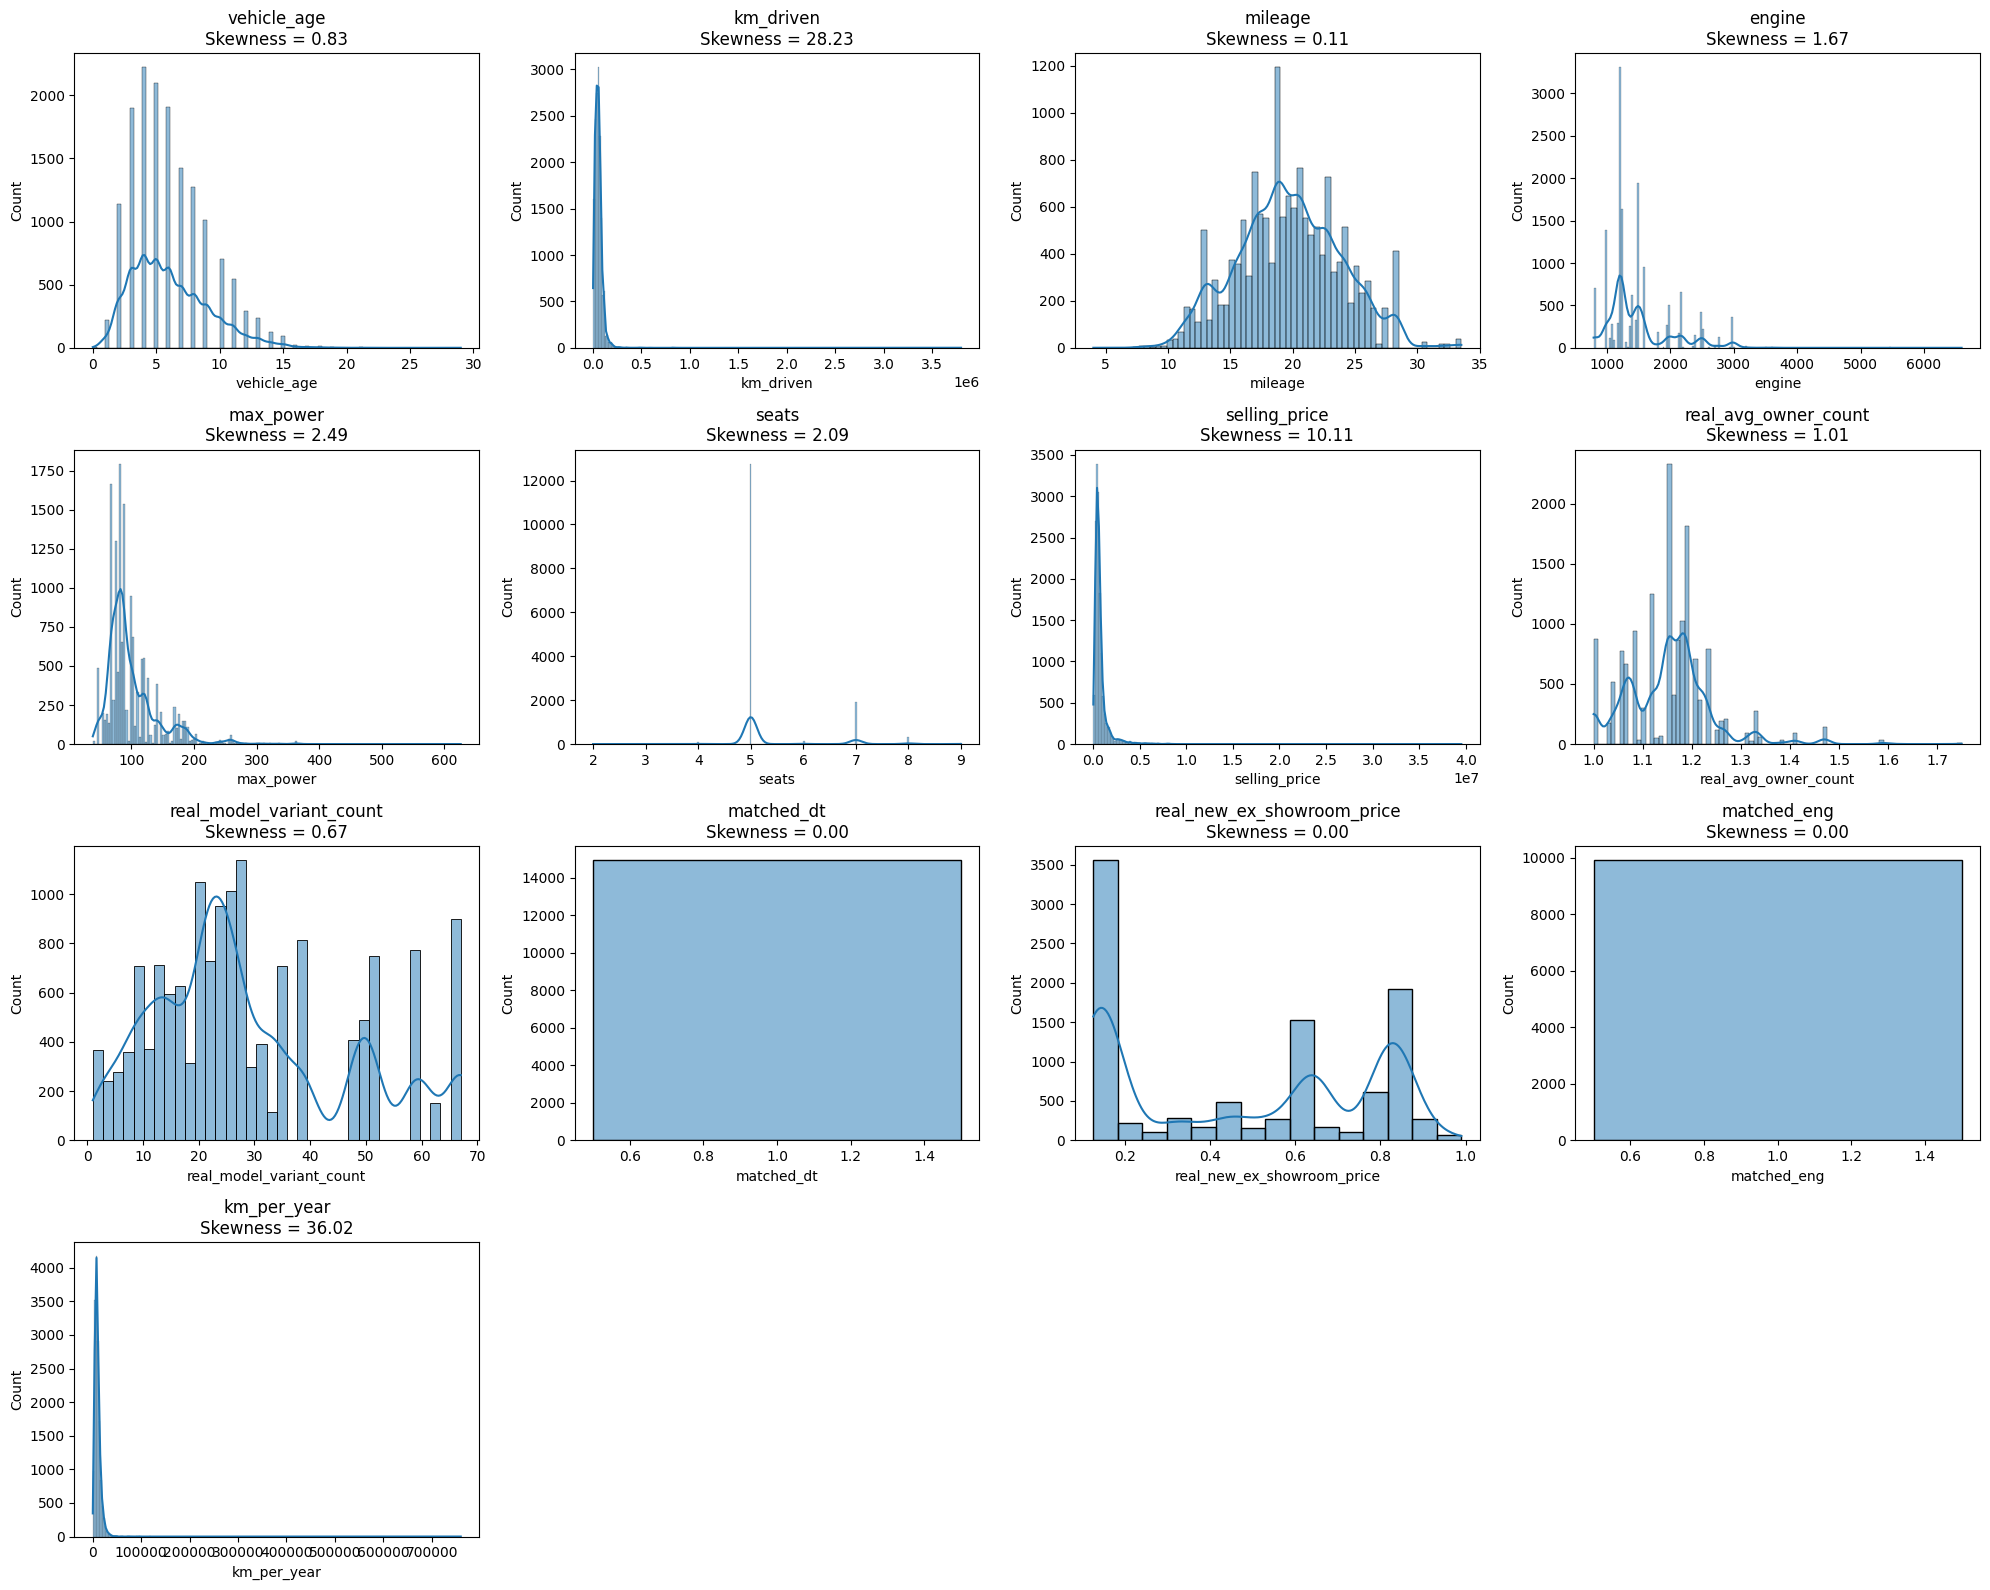

In [23]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for ax, col in zip(axes.flatten(), numerical_columns):

    data = pd.to_numeric(df[col], errors="coerce").dropna()

    skew_value = data.skew()

    sns.histplot(data, kde=True, ax=ax)

    ax.set_title(f"{col}\nSkewness = {skew_value:.2f}")

for ax in axes.flatten()[len(numerical_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [24]:
kurtosis = df[numerical_columns].kurtosis()

print("Kurtosis of numerical variables:")
print(kurtosis.sort_values(ascending=False).round(3))

Kurtosis of numerical variables:
km_per_year                   2547.266
km_driven                     1845.455
selling_price                  284.282
max_power                       11.945
engine                           4.372
real_avg_owner_count             3.910
seats                            3.518
vehicle_age                      0.763
matched_eng                      0.000
matched_dt                       0.000
mileage                         -0.162
real_model_variant_count        -0.474
real_new_ex_showroom_price      -1.661
dtype: float64


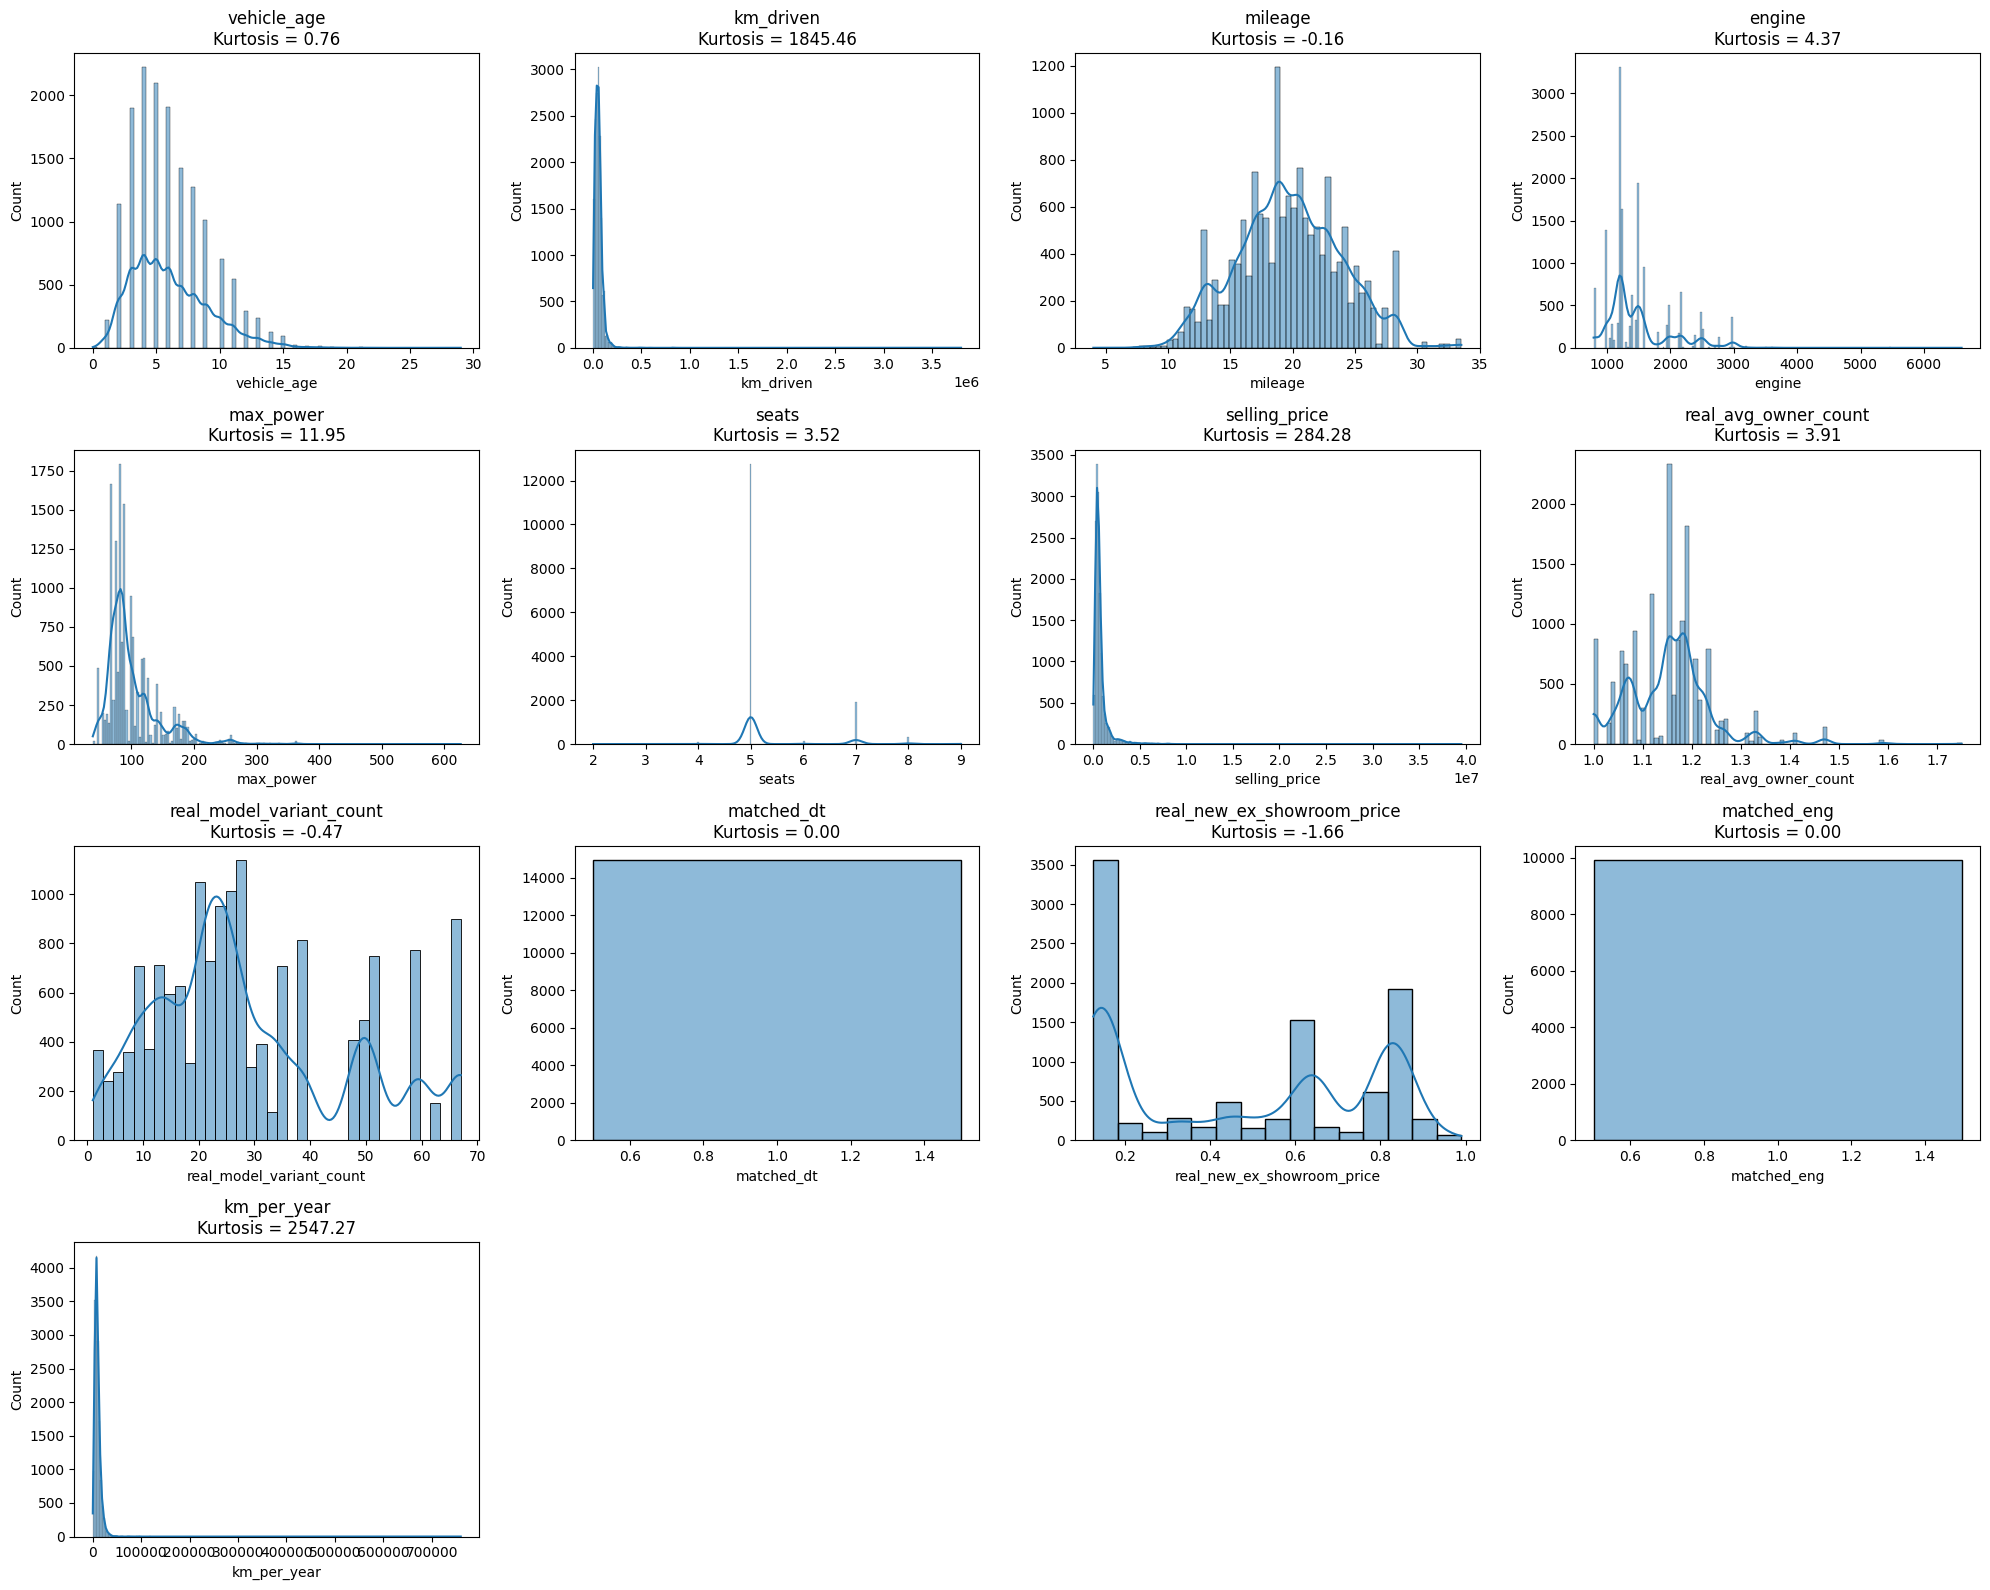

In [25]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for ax, col in zip(axes.flatten(), numerical_columns):

    data = pd.to_numeric(df[col], errors="coerce").dropna()

    kurt_value = data.kurtosis()

    sns.histplot(data, kde=True, ax=ax)

    ax.set_title(f"{col}\nKurtosis = {kurt_value:.2f}")

for ax in axes.flatten()[len(numerical_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [26]:
summary = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Standard Deviation": df[numerical_columns].std(),
    "Skewness": df[numerical_columns].skew(),
    "Kurtosis": df[numerical_columns].kurtosis()
})

display(summary.round(2))

,Mean,Median,Standard Deviation,Skewness,Kurtosis
vehicle_age,6.04,6.00,3.02,0.83,0.76
km_driven,55639.58,50000.00,51766.30,28.23,1845.46
mileage,19.70,19.67,4.17,0.11,-0.16
engine,1486.17,1248.00,520.42,1.67,4.37
max_power,100.61,88.50,42.92,2.49,11.95
seats,5.33,5.00,0.81,2.09,3.52
selling_price,774701.45,559000.00,894676.08,10.11,284.28
real_avg_owner_count,1.15,1.15,0.09,1.01,3.91
real_model_variant_count,29.17,25.00,17.57,0.67,-0.47
matched_dt,1.00,1.00,0.00,0.00,0.00
